# CRC Atera 教程 03：从已验收 ROI 到 GHIST+ 模型输入

**目标**：学会“一份空间组学数据要怎样被改造成图像模型能吃的输入”，并亲手复算每一步的数值闭合。

**这不是**：模型推理、表达预测、微调、训练或任何疾病结论。教程结束时**仍然没有 GHIST+ 预测结果**。

**前置条件**：教程 01、02 的输出，以及 `CRC_Atera/05_ghist_roi_adapter/` 里已经验收过的 ROI 产物。

> 本教程在**同一个 Windows CPU 环境**里复算已验收产物，因此不需要 GPU，也不重跑 71 GB 外包解压。真正跑 GHIST+ 官方加载器和模型在 WSL 环境中完成；本教程会读它的验收报告来说明接口契约。

## 0. 先看全景：数据要变成什么？

GHIST+ 的输入不是"表达矩阵"，而是**三件必须严格对齐的东西**：

```text
① H&E 图像      he_roi_0p5um.tif          (2400×2400, 0.5 µm/px)
② 核掩膜        nuclei_roi_labels_uint32.tif (每像素一个 label)
③ 核坐标/大小   matched_nuclei_filtered.csv  (c_id ↔ label ↔ Atera cell_id)

      + 观测表达（仅用于验证行对应，不是模型输入）
      atera_observed_expression_matched_genes.csv  (10,795 × 1,245)
```

关键点：**坐标空间必须一致**。这是整个适配里最容易出错、也最难发现错误的地方。

| 文件 | 坐标单位 |
|---|---|
| `nucleus_coordinates.csv` 的 `roi_x_px/roi_y_px` | ROI 像素（0.5 µm/px） |
| `nucleus_coordinates.csv` 的 `he_x_px/he_y_px` | 全图 H&E 像素 |
| `cell_coords.csv` 的 `x_coord/y_coord` | **ROI 像素**（喂给官方加载器） |
| `ghist_cells.csv` 的 `x_coord/y_coord` | **全图 H&E 像素** |

同一个对象在两张表里坐标数值不同，是因为它们服务于不同下游。选错空间不会报错，只会静默错位——所以官方加载器用 `cell_coords_id_space='histology'` 显式声明，并自己做对齐抽查。

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODULE_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'scripts' / 'atera_helpers.py').is_file()
                   and p.name == 'crc-atera-learning'), None)
assert MODULE_DIR is not None, '请从 crc-atera-learning 目录运行 notebook'
sys.path.insert(0, str(MODULE_DIR / 'scripts'))

CRC_DIR = MODULE_DIR.parent
ROI_DIR = CRC_DIR / '05_ghist_roi_adapter'
ROI_IN = ROI_DIR / 'input'
ROI_OUT = ROI_DIR / 'output'
SCRIPT_DIR = MODULE_DIR / 'scripts'
OUT_DIR = MODULE_DIR / 'output' / 'ghist_input'
FIG_DIR = OUT_DIR / 'figures'
TAB_DIR = OUT_DIR / 'tables'
for d in (OUT_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# 图件用英文，避免不同系统的中文字体造成缺字。
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 120, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('Python:', sys.executable)
print('Module:', MODULE_DIR)
print('ROI products:', ROI_DIR)

Python: D:\Deep_learning\CRC_Atera_Learning\.venv\Scripts\python.exe
Module: E:\Atera_v1_example\CRC_Atera\crc-atera-learning
ROI products: E:\Atera_v1_example\CRC_Atera\05_ghist_roi_adapter


## 1. 读入上游验收报告：先相信记录，再复算

上游的 `roi_export_report.json` 是 05 模块的正式验收记录。本教程不修改它，只读取其中的几何常量与验收数值，然后**独立重算**并比较。

> 原则：写代码时"我算出来应该是 X"不算验证；必须和另一个独立来源的数值逐项比对。这里我们用上游报告 + 官方加载器报告两份独立记录交叉核对。

In [2]:
report = json.loads((ROI_OUT / 'roi_export_report.json').read_text(encoding='utf-8'))
loader_report = json.loads((ROI_OUT / 'ghist_dataset_smoke' / 'report.json').read_text(encoding='utf-8'))

print('ROI status           :', report['status'])
print('validation status    :', report['validation_status'])
print('loader status        :', loader_report['status'])
print('patches / nuclei     :', loader_report['n_patches'], '/', loader_report['n_nuclei'])
print('model forward run    :', loader_report['model_forward_run'])
print('reference priors used:', loader_report['reference_priors_used'])

geo = report['geometry']
print()
print('ROI origin (um)      :', report['roi']['x0_atera_um'], report['roi']['y0_atera_um'])
print('ROI side (um)        :', report['roi']['side_um'], '-> area', report['roi']['area_mm2'], 'mm2')
print('output shape (yx)    :', geo['output_shape_yx'], 'pixel um', geo['pixel_um_xy'])
print('um -> fixed px scale :', geo['summary_um_to_fixed_scale'])
print('model genes          :', report['n_model_genes'])
print('exact gene matches   :', report['n_exact_gene_matches'])
print('unresolved genes     :', report['n_unresolved_genes'])

assert loader_report['model_forward_run'] is False
assert loader_report['reference_priors_used'] is False
assert report['roi']['area_mm2'] == 1.44
assert geo['output_shape_yx'] == [2400, 2400]
assert geo['pixel_um_xy'] == [0.5, 0.5]
assert report['n_model_genes'] == 1275
print()
print('OK: 这份报告记录的是"输入已就绪"，不是"模型已运行"。')

ROI status           : input_qc_passed_local_segmentation_limits
validation status    : numerical_and_visual_passed_local_segmentation_limits
loader status        : test_mode_loader_smoke_passed
patches / nuclei     : 169 / 10795
model forward run    : False
reference priors used: False

ROI origin (um)      : 1500.0 2000.0
ROI side (um)        : 1200.0 -> area 1.44 mm2
output shape (yx)    : [2400, 2400] pixel um [0.5, 0.5]
um -> fixed px scale : 4.7060546875
model genes          : 1275
exact gene matches   : 1245
unresolved genes     : 30

OK: 这份报告记录的是"输入已就绪"，不是"模型已运行"。


## 2. 复算坐标闭合（本教程最重要的一节）

Atera 的坐标有三层，教程 02 只用到第一层：

```text
Atera µm 坐标  ──×4.7060546875──▶  fixed 原生像素  ──M⁻¹──▶  全图 H&E 像素
     ▲                                                              │
     └──────  ROI 局部像素（÷2.35302734375）◀──T⁻¹───────────────┘
```

两个尺度系数不要混：

- **4.7060546875**：µm → fixed 原生像素；
- **2.35302734375**：ROI 像素 → fixed 原生像素（= 4.7060546875 × 0.5 µm/px）。

**像素中心约定**：局部索引 `i` 的中心在 `(i+0.5, i+0.5)`，不是 `i`。差半个像素在 2400 px 网格上就是 1.2 µm 的系统偏移。

下面用报告里给的仿射矩阵，**独立重算**每个核的坐标，并和保存值逐项比较。

In [3]:
T = np.array([[report['roi']['side_um'] * geo['summary_um_to_fixed_scale'] / 2400, 0,
                report['roi']['x0_atera_um'] * geo['summary_um_to_fixed_scale']],
               [0, report['roi']['side_um'] * geo['summary_um_to_fixed_scale'] / 2400,
                report['roi']['y0_atera_um'] * geo['summary_um_to_fixed_scale']], [0, 0, 1]])
M = np.array(geo['he_to_fixed_matrix'], dtype=float)
hx0, hy0 = geo['he_crop_offset_xy']

roi_px_to_fixed = np.diag(T[:2, :2])
print('ROI px -> fixed px :', roi_px_to_fixed, ' (期望 2.35302734375)')
assert abs(roi_px_to_fixed[0] - 2.35302734375) < 1e-12

# 仿射链：ROI 像素 -> fixed -> H&E 裁剪局部
warp = np.linalg.inv(M) @ T
warp[:2, 2] -= [hx0, hy0]
assert np.allclose(warp, geo['output_to_he_crop_matrix'], rtol=0, atol=1e-9)
print('output_to_he_crop 复算一致')

coords = pd.read_csv(ROI_IN / 'nucleus_coordinates.csv')
print('核对象数:', len(coords))
roi_xy = coords[['roi_x_px', 'roi_y_px']].to_numpy()
fixed_xy = coords[['fixed_x_px', 'fixed_y_px']].to_numpy()
he_xy = coords[['he_x_px', 'he_y_px']].to_numpy()

# 正向：ROI 像素中心 -> fixed
fwd_fixed = roi_xy @ T[:2, :2].T + T[:2, 2]
err_fixed = np.abs(fwd_fixed - fixed_xy).max()
# 反向：fixed -> H&E 全图
inv_M = np.linalg.inv(M)
fwd_he = np.c_[fixed_xy, np.ones(len(coords))] @ inv_M[:2].T
err_he = np.abs(fwd_he - he_xy).max()
# 反向再回到 ROI：fixed -> H&E -> (加回裁剪偏移) -> fixed -> ROI
he_crop = he_xy - [hx0, hy0]
back_fixed = np.c_[he_crop + [hx0, hy0], np.ones(len(coords))] @ M[:2].T
back_roi = np.c_[back_fixed, np.ones(len(coords))] @ np.linalg.inv(T)[:2].T
err_roundtrip = np.abs(back_roi - roi_xy).max()

print()
print('ROI px -> fixed px  最大误差:', err_fixed)
print('fixed -> H&E px     最大误差:', err_he)
print('H&E -> fixed -> ROI 最大误差:', err_roundtrip)
assert err_fixed < 1e-6 and err_he < 1e-6 and err_roundtrip < 1e-6
print()
print('OK: 坐标链闭合到 1e-6 像素以内，远小于 0.5 µm/px 的像素尺寸。')

ROI px -> fixed px : [2.35302734 2.35302734]  (期望 2.35302734375)
output_to_he_crop 复算一致
核对象数: 10795

ROI px -> fixed px  最大误差: 1.8189894035458565e-12
fixed -> H&E px     最大误差: 7.275957614183426e-12
H&E -> fixed -> ROI 最大误差: 5.9117155615240335e-12

OK: 坐标链闭合到 1e-6 像素以内，远小于 0.5 µm/px 的像素尺寸。


### 为什么"误差 1e-12"是可信的，而"误差 0"才可疑

如果只是把保存的 `roi_x_px` 拿来减 `he_x_px`，那当然对不上。真正有意义的检验是：**用原始仿射矩阵从头再算一遍**——从 µm 出发、经过 fixed、到 H&E——看是否回到保存值。上面的 `err_roundtrip` 就是这个检验。

数值越小越好，但要注意区分：

- **1e-12 量级**：来自浮点舍入，说明两套实现用了同一套数学；
- **恰好 0**：说明是逐位复制同一份数据（例如 H&E 重采样后逐像素一致），这时必须确认重采样代码确实独立。

下一步我们用**独立路径**重采样 H&E 来区分这两种情况。

## 3. 核掩膜与标签：每个像素只属于一个核

核掩膜 `nuclei_roi_labels_uint32.tif` 是单通道 uint32 标签图：0 表示背景，正整数是核的 `mask_label`。

要验证的是三件事：
1. 标签集合与坐标表一一对应（没有孤立标签，也没有表里没有的标签）；
2. 每个核的像素数 = 官方加载器用的 `size_pix_histology`；
3. 标签的**质心**与保存的核坐标一致（说明标签图和坐标表是同一坐标系）。

这里我们从标签图本身重算质心，而不是相信坐标表里的 `roi_x_px`。

In [4]:
import tifffile
from scipy import ndimage

mask = tifffile.imread(ROI_IN / 'nuclei_roi_labels_uint32.tif')
he = tifffile.imread(ROI_IN / 'he_roi_0p5um.tif')
print('mask:', mask.shape, mask.dtype, '| he:', he.shape, he.dtype)
assert mask.shape == (2400, 2400) and mask.dtype == np.uint32
assert he.shape == (2400, 2400, 3) and he.dtype == np.uint8

labels = coords['roi_mask_label'].to_numpy(dtype=np.uint32)
mask_labels = np.unique(mask)
mask_labels = mask_labels[mask_labels != 0]
print('标签数（坐标表）:', len(labels), '（掩膜图）:', len(mask_labels))
assert set(labels.tolist()) == set(mask_labels.tolist())

areas = ndimage.sum_labels(np.ones(mask.shape, dtype=np.uint8), mask, labels)
com_yx = np.asarray(ndimage.center_of_mass(np.ones(mask.shape, dtype=np.uint8), mask, labels))
com_xy = com_yx[:, ::-1]
centroid_err = np.linalg.norm(com_xy - roi_xy, axis=1)
print('标签像素数 == size_pix_histology:', np.array_equal(areas.astype(np.int64),
      coords['size_pix_histology'].to_numpy(dtype=np.int64)) if 'size_pix_histology' in coords
      else np.array_equal(areas.astype(np.int64), pd.read_csv(ROI_IN / 'matched_nuclei_filtered.csv')['size_pix_histology'].to_numpy(dtype=np.int64)))
print('质心偏差 中位数 %.3f px / p95 %.3f px / 最大 %.3f px' %
      (np.median(centroid_err), np.quantile(centroid_err, .95), centroid_err.max()))
assert centroid_err.max() < 5.0
assert (areas >= 10).all()
print('OK: 标签、像素面积与坐标表互相自洽。')

mask: (2400, 2400) uint32 | he: (2400, 2400, 3) uint8
标签数（坐标表）: 10795 （掩膜图）: 10795


标签像素数 == size_pix_histology: True
质心偏差 中位数 0.714 px / p95 0.856 px / 最大 1.235 px
OK: 标签、像素面积与坐标表互相自洽。


## 4. 三张 ID 表的关系：最容易出错的一环

同一个核在不同文件里有不同的标识符：

| 文件 | ID 列 | 含义 |
|---|---|---|
| `nucleus_coordinates.csv` | `cell_id` | Atera 整数 ID（如 4294979055） |
| `nucleus_coordinates.csv` | `barcode` | 10x barcode 字符串（如 `acmjdhll-1`） |
| `matched_nuclei_filtered.csv` | `id_xenium` | Atera 整数 ID |
| `matched_nuclei_filtered.csv` | `c_id` / `id_histology` | 掩膜标签号 |
| `ghist_cells.csv` | `original_cell_id` | Atera 整数 ID |
| `ghist_cells.csv` | `c_id` | 掩膜标签号 |

**`c_id` 不是 Atera 的 `cell_id`**：它是 ROI 内重新编号的掩膜标签，从 5260 起跳（因为它取自原始核掩膜的全局标签）。

连表必须走 `barcode` 或 `cell_id`，绝不能拿整数 ID 去对 `barcode` 字符串——那正是教程 01 里专门强调过的坑。

下面验证所有这些映射都是**双射**（一一对应且方向唯一）。

In [5]:
nuc = pd.read_csv(ROI_IN / 'nucleus_coordinates.csv')
meta = pd.read_csv(ROI_IN / 'matched_nuclei_filtered.csv')
ghist = pd.read_csv(ROI_IN / 'ghist_cells.csv')
cc = pd.read_csv(ROI_IN / 'cell_coords.csv')

print('行数: nucleus_coordinates=%d, matched_nuclei=%d, ghist_cells=%d, cell_coords=%d'
      % (len(nuc), len(meta), len(ghist), len(cc)))

# Atera cell_id <-> 掩膜标签
assert np.array_equal(meta['c_id'].to_numpy(), nuc['roi_mask_label'].to_numpy())
assert np.array_equal(meta['id_xenium'].to_numpy(dtype=np.uint64), nuc['cell_id'].to_numpy(dtype=np.uint64))
# ghist_cells 与 nucleus_coordinates 同序
assert np.array_equal(ghist['original_cell_id'].to_numpy(dtype=np.uint64), nuc['cell_id'].to_numpy(dtype=np.uint64))
assert np.array_equal(ghist['c_id'].to_numpy(), nuc['roi_mask_label'].to_numpy())
# cell_coords 用 id_histology 对应掩膜标签
assert np.array_equal(cc['id_histology'].to_numpy(), nuc['roi_mask_label'].to_numpy())

for name, series in [('nuc.cell_id', nuc['cell_id']), ('nuc.barcode', nuc['barcode']),
                     ('nuc.mask_label', nuc['roi_mask_label']), ('meta.c_id', meta['c_id'])]:
    assert series.is_unique, name
print('所有 ID 列均唯一')

# cell_coords 用 ROI 像素，ghist_cells 的 x_coord/y_coord 用 H&E 全图像素
cc_roi = cc[['x_coord', 'y_coord']].to_numpy()
gh_he = ghist[['x_coord', 'y_coord']].to_numpy()
print()
print('cell_coords  x 范围: %.1f .. %.1f (ROI 像素, 上限 2400)' % (cc_roi[:, 0].min(), cc_roi[:, 0].max()))
print('ghist_cells  x 范围: %.1f .. %.1f (H&E 全图像素)' % (gh_he[:, 0].min(), gh_he[:, 0].max()))
assert cc_roi.max() < 2400 and gh_he.max() > 2400
print('OK: 确认两张表处于不同坐标空间；官方加载器必须声明 cell_coords_id_space。')

行数: nucleus_coordinates=10795, matched_nuclei=10795, ghist_cells=10795, cell_coords=10795
所有 ID 列均唯一

cell_coords  x 范围: 4.5 .. 2395.6 (ROI 像素, 上限 2400)
ghist_cells  x 范围: 16461.1 .. 20823.3 (H&E 全图像素)
OK: 确认两张表处于不同坐标空间；官方加载器必须声明 cell_coords_id_space。


## 5. 观测表达：只是"行对应"的验证材料

上游导出了 `10,795 × 1,245` 的观测表达矩阵。它**不是** GHIST+ 的输入，也不是预测结果，只用来证明三件事：

1. 每一行确实对应 ROI 内的一个核；
2. 每个基因值与原始 CSR 矩阵完全一致；
3. 基因符号与官方模型的 1,275 基因表的对应关系明确。

本教程会**独立重算**：从原始 `cell_feature_matrix.zarr.zip` 按 `expression_row` 取行、按基因符号取列，然后与导出表逐元素比较。

> 注意：读取整个 44.7 万细胞的表达矩阵约需 20 秒并占用约 3 GB 内存（稀疏）。这是可接受的，因为稀疏矩阵不会稠密化。

In [6]:
expr = pd.read_csv(ROI_IN / 'atera_observed_expression_matched_genes.csv', index_col=0)
gene_map = pd.read_csv(ROI_OUT / 'tables' / 'roi_gene_map.csv')
print('导出表达表:', expr.shape)
print('第一列名:', expr.index.name, '| 前 3 行索引:', list(expr.index[:3]))

matched = gene_map.loc[gene_map['matching_rule'] == 'exact_symbol']
print('基因映射表:', gene_map.shape, '| 规则:', gene_map['matching_rule'].value_counts().to_dict())
assert len(matched) == expr.shape[1]
assert np.array_equal(matched['model_gene'].to_numpy(dtype=str), expr.columns.to_numpy(dtype=str))

from zarr.storage import ZipStore
import anndata as ad

matrix_path = MODULE_DIR / 'input' / 'cell_feature_matrix.zarr.zip'
print('读取原始矩阵:', matrix_path.name)
with ZipStore(matrix_path, mode='r') as store:
    adata = ad.read_zarr(store)
print('原始矩阵:', adata.shape, type(adata.X).__name__, '| nnz =', adata.X.nnz)

obs_cell_id = adata.obs['cell_id'].to_numpy(dtype=np.uint64)
row_of = pd.Series(np.arange(adata.n_obs), index=obs_cell_id)
expr_rows = coords['expression_row'].to_numpy(dtype=np.int64)
assert np.array_equal(obs_cell_id[expr_rows], nuc['cell_id'].to_numpy(dtype=np.uint64))
print('expression_row -> cell_id 一一对应 OK')

feature_names = adata.var['feature_name'].astype('object').str.strip()
feature_ids = adata.var['feature_id'].astype('object').str.strip()
col_of = pd.Series(np.arange(adata.n_vars), index=feature_names.to_numpy())
gene_cols = col_of.loc[expr.columns.to_numpy(dtype=str)].to_numpy()

sub = adata.X[expr_rows][:, gene_cols].toarray()
exported = expr.to_numpy()
delta = np.abs(sub - exported).max()
print()
print('独立重算 vs 导出表，最大绝对误差:', delta)
print('总 counts: 重算 %d / 导出 %d' % (sub.sum(), exported.sum()))
assert delta == 0.0
assert sub.sum() == exported.sum()
print('OK: 表达值逐位一致（稀疏矩阵按行索引取子集，未稠密化全矩阵）。')

导出表达表: (10795, 1245)
第一列名: cell_id | 前 3 行索引: [4341708731, 4341720362, 4341790583]
基因映射表: (1275, 4) | 规则: {'exact_symbol': 1245, 'unresolved': 30}


读取原始矩阵: cell_feature_matrix.zarr.zip


原始矩阵: (446777, 24677) csr_matrix | nnz = 1313675832
expression_row -> cell_id 一一对应 OK



独立重算 vs 导出表，最大绝对误差: 0
总 counts: 重算 8043562 / 导出 8043562
OK: 表达值逐位一致（稀疏矩阵按行索引取子集，未稠密化全矩阵）。


## 6. 30 个基因为什么没对上？（HGNC 改名 + 面板差异）

模型面板是 1,275 个基因，Atera 里精确同名有 1,245 个，剩 **30 个**没匹配上。这 30 个里其实混着**两种完全不同**的原因：

**原因一：HGNC 改名后的旧符号**（模型用旧名，Atera 用新名）。例如 `KARS` 在现代 HGNC 里叫 `KARS1`（HGNC:6215），`NARS` → `NARS1`，`LRMP` → `IRAG2`。这些**可以恢复**：同一个基因，只是符号版本不同。

**原因二：Atera 的 18,049 基因面板里根本没有**（如 `MUC6`、`APOD`、`EIF4A1`）。这些**无法恢复**，只能标为缺失。

区分这两者很重要：把改名基因误判为"缺失"会低估 1,245 这个数字的意义；把缺失基因硬凑成某个近似符号则是造假。

**这里有一个必须避开的陷阱**：`CAP1` 看起来很像 `CAPN1`（只差一个 N），但查 HGNC 会发现 `CAP1`（HGNC:20040，ENSG00000131236）与 `CAPN1`（ENSG00000014216）是**两个不同的基因**，Ensembl ID 不一致。所以"看起来像"不能作为匹配依据。

下面的查证结果已由 HGNC 官方 REST API 取得并冻结在 `scripts/gene_symbol_hgnc_lookup.json`（含 HGNC ID 与 Ensembl ID）。判定规则是：**基因身份由 Ensembl ID 决定，不由符号相似度决定**。

In [7]:
gene_features = adata.var['feature_type'].astype('object').str.strip().eq('Gene Expression')
panel = set(feature_names[gene_features].tolist())
print('Atera 基因面板大小:', len(panel))

unresolved = gene_map.loc[gene_map['matching_rule'] != 'exact_symbol'].copy()
print('未匹配基因数:', len(unresolved))

# 读取已冻结的 HGNC 查证记录（由 scripts/gene_symbol_hgnc_lookup.json 提供，
# 来源 rest.genenames.org，含 HGNC ID 与 Ensembl gene ID）
with open(SCRIPT_DIR / 'gene_symbol_hgnc_lookup.json', encoding='utf-8') as fh:
    hgnc = json.load(fh)['records']

# Ensembl gene ID -> Atera 面板里的现行符号（身份判定的唯一依据）
atera_by_ensembl = {}
for ens, name in zip(feature_ids[gene_features], feature_names[gene_features]):
    atera_by_ensembl.setdefault(str(ens).strip(), str(name).strip())

rows = []
for _, r in unresolved.iterrows():
    g = str(r['model_gene'])
    rec = hgnc.get(g, {})
    ens = rec.get('hgnc_ensembl_gene_id')
    atera_symbol = atera_by_ensembl.get(ens) if ens else None
    renamed = bool(rec.get('relation_to_model_symbol') == 'previous_symbol')
    rows.append({
        'model_gene': g,
        'hgnc_current_symbol': rec.get('hgnc_current_symbol') or 'not_applicable',
        'hgnc_id': rec.get('hgnc_id') or 'not_applicable',
        'hgnc_ensembl_gene_id': ens or 'not_applicable',
        'relation': rec.get('relation_to_model_symbol') or 'not_applicable',
        'atera_symbol_same_ensembl': atera_symbol or 'not_in_panel',
        'in_atera_panel': atera_symbol is not None,
        'resolution': 'hgnc_renamed' if (renamed and atera_symbol) else 'not_in_panel',
    })

gene_status = pd.DataFrame(rows).sort_values(['resolution', 'model_gene'])
n_renamed = int((gene_status['resolution'] == 'hgnc_renamed').sum())
n_absent = int((gene_status['resolution'] == 'not_in_panel').sum())
print()
print('改名可恢复:', n_renamed, '| 面板中确实没有:', n_absent)

# 一致性自检：改名基因必须 Ensembl ID 一致，且该符号确实在 Atera 面板中
for _, r in gene_status[gene_status['resolution'] == 'hgnc_renamed'].iterrows():
    assert r['atera_symbol_same_ensembl'] in panel, r['model_gene']
    assert r['model_gene'] not in panel, f"{r['model_gene']} 不应同时精确匹配"
assert n_renamed + n_absent == len(unresolved), '改名 + 缺失 应等于未匹配总数'
assert n_renamed == 9, f'HGNC 改名可恢复数应为 9，实际 {n_renamed}'
assert n_absent == 21, f'面板缺失数应为 21，实际 {n_absent}'
print('自检通过：9 个改名基因的 Ensembl ID 在 Atera 面板中唯一命中，且原符号确不在面板中。')

gene_status.to_csv(TAB_DIR / 'gene_panel_gap.csv', index=False)
print(gene_status.to_string(index=False))
print()
print('注意: "not_in_panel" 的 21 个基因在本教程不做近似匹配。')

Atera 基因面板大小: 18049
未匹配基因数: 30

改名可恢复: 9 | 面板中确实没有: 21
自检通过：9 个改名基因的 Ensembl ID 在 Atera 面板中唯一命中，且原符号确不在面板中。
model_gene hgnc_current_symbol    hgnc_id hgnc_ensembl_gene_id        relation atera_symbol_same_ensembl  in_atera_panel   resolution
    ATP5MD              ATP5MK HGNC:30889      ENSG00000173915 previous_symbol                    ATP5MK            True hgnc_renamed
  C1orf194             CFAP276 HGNC:32331      ENSG00000179902 previous_symbol                   CFAP276            True hgnc_renamed
    FAM49A               CYRIA HGNC:25373      ENSG00000197872 previous_symbol                     CYRIA            True hgnc_renamed
      KARS               KARS1  HGNC:6215      ENSG00000065427 previous_symbol                     KARS1            True hgnc_renamed
      LARS               LARS1  HGNC:6512      ENSG00000133706 previous_symbol                     LARS1            True hgnc_renamed
      LRMP               IRAG2  HGNC:6690      ENSG00000118308 previous_symbol          

### 为什么这里不做"猜测匹配"

一个常见的错误做法：对没匹配上的基因找名字最接近的符号接上去。这会制造**看起来完整、实则错误**的输入矩阵——下游模型会把它当成真实表达，而它其实来自另一个基因。

正确做法分两步：

1. **可查证的改名**：用权威符号表（HGNC）确认对应关系，逐条记录来源；
2. **确实缺失的**：标为缺失。如果模型要求完整 1,275 基因输入，只能选择：
   - 官方模型自带的缺失值处理（GHIST+ 配置里若有），或
   - 用训练集同源的统计量填补（需要作者提供的参考先验），或
   - 缩小面板并相应调整模型输入层（需要改代码，偏离原模型）。

当前状态是**尚未冻结**：这 30 个基因的补齐策略还没定，因此还没有"冻结的 Atera 专用 M0 输入配置"。

## 7. 官方加载器接口：我们必须满足什么契约

上游已在 WSL 中用 GHIST+ 官方代码实际加载过这份 ROI。本教程不重跑（需要 torch + 官方代码），但要读懂它的验收报告，因为**接口契约决定我们导出什么**。

In [8]:
cv = loader_report['coordinate_validation']
print('loader status        :', loader_report['status'])
print('patches              :', loader_report['n_patches'])
print('nuclei               :', loader_report['n_nuclei'])
print('coordinate units     :', loader_report['coordinate_units'])
print('regions_test         :', loader_report['regions_test'])
print()
print('坐标 ID 空间:', cv['cell_coords_id_space'], '(请求:', cv['cell_coords_id_space_requested'] + ')')
print('ID 列          :', cv['cell_coords_id_column'])
print('匹配到的 ID 数 :', cv['matched_histology_ids'], '/ CSV 行数', cv['csv_coordinates'])
print('坐标覆盖率      :', cv['csv_coordinate_coverage'])
print('unresolved      :', cv['unresolved'])
print('centroid_filled :', cv['centroid_filled'])
print()
print('对齐抽查:')
for k, v in cv['alignment'].items():
    print('  %-22s %s' % (k, v))

assert cv['unresolved'] == 0 and cv['centroid_filled'] == 0
assert cv['alignment']['status'] == 'passed'
assert cv['alignment']['max_error_px'] < cv['alignment']['tolerance_px']
assert cv['csv_coordinate_coverage'] == 1.0
assert loader_report['n_nuclei'] == len(nuc)
print()
print('OK: 官方加载器能在不做任何"质心填补"的前提下读全 10,795 个坐标。')

loader status        : test_mode_loader_smoke_passed
patches              : 169
nuclei               : 10795
coordinate units     : registered ROI pixels; 0.5 um/pixel
regions_test         : {'divisions': [[0.0, 1.0]]}

坐标 ID 空间: histology (请求: histology)
ID 列          : id_histology
匹配到的 ID 数 : 10795 / CSV 行数 10795
坐标覆盖率      : 1.0
unresolved      : 0
centroid_filled : 0

对齐抽查:
  status                 passed
  method                 memory_mapped_local_windows
  cell_coords_id_space   histology
  sampled_labels         2048
  window_radius_px       64
  median_error_px        0.7120175576167457
  p95_error_px           0.8540507180149817
  max_error_px           1.0966641343891337
  tolerance_px           5.0

OK: 官方加载器能在不做任何"质心填补"的前提下读全 10,795 个坐标。


### `unresolved = 0` 和 `centroid_filled = 0` 为什么重要

官方加载器在找不到某个核的坐标时，可以**用核掩膜的质心补一个**。这看起来无害，实际上很危险：质心不是细胞的真实位置，会给模型一个"看起来对、其实错"的空间信息。

我们的数据里 **10,795 个核全部有真实坐标**（`cell_coords.csv` 覆盖率 1.0，`unresolved = 0`），所以不需要任何填补。对齐抽查的最大误差 1.097 像素 < 5 像素容差。

**这是"我们提供了正确输入"的证据，不是"模型预测正确"的证据。**

## 8. 可视化验收：肉眼再看一遍

数值一致不等于图像对。这里我们做两件事：
1. 叠加核边界到 H&E 上，看整体有没有系统性平移；
2. 放大几个区域，看局部是"拥挤/欠分割"这类**分割本身的问题**，还是"整体偏移"这类**配准问题**。

这两类问题的处理方式完全不同，必须区分。

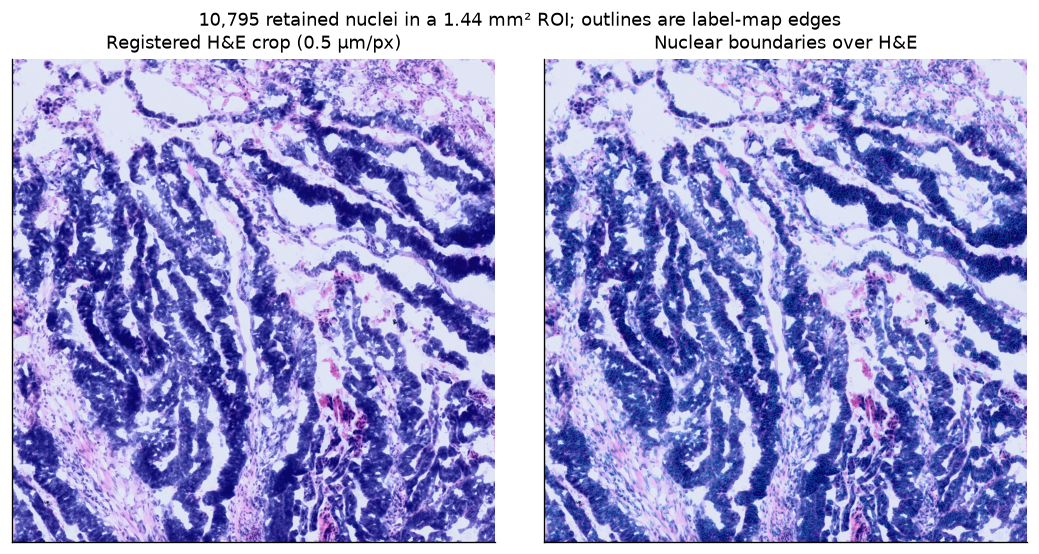

In [9]:
from PIL import Image

nuclear = mask > 0
boundary = nuclear & ((mask != np.roll(mask, 1, axis=0)) | (mask != np.roll(mask, 1, axis=1)))
preview = he.copy()
preview[boundary] = [0, 190, 230]

fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.6))
axes[0].imshow(he)
axes[0].set_title('Registered H&E crop (0.5 µm/px)')
axes[1].imshow(preview)
axes[1].set_title('Nuclear boundaries over H&E')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('10,795 retained nuclei in a 1.44 mm² ROI; outlines are label-map edges', y=0.99)
fig.tight_layout()
fig.savefig(FIG_DIR / 'roi_nuclei_overview.png', bbox_inches='tight')
plt.show()

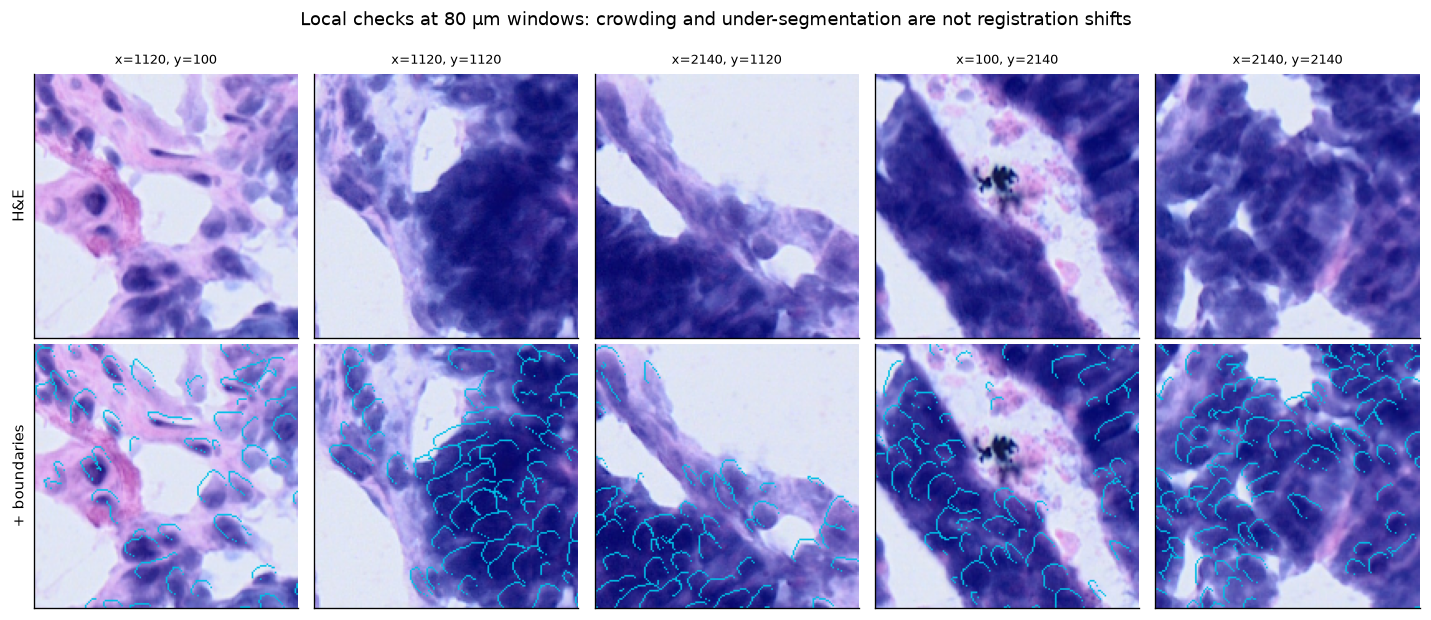

窗口坐标单位为 ROI 像素；每格 160 px = 80 µm。


In [10]:
# 局部放大：区分"拥挤/欠分割"与"整体偏移"
windows = [(1120, 100), (1120, 1120), (2140, 1120), (100, 2140), (2140, 2140)]
fig, axes = plt.subplots(2, 5, figsize=(12.0, 5.2))
for j, (x, y) in enumerate(windows):
    axes[0, j].imshow(he[y:y+160, x:x+160])
    axes[0, j].set_title(f'x={x}, y={y}', fontsize=8)
    axes[1, j].imshow(preview[y:y+160, x:x+160])
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('H&E', fontsize=9)
axes[1, 0].set_ylabel('+ boundaries', fontsize=9)
fig.suptitle('Local checks at 80 µm windows: crowding and under-segmentation are not registration shifts', y=0.995)
fig.tight_layout()
fig.savefig(FIG_DIR / 'roi_nuclei_local_checks.png', bbox_inches='tight')
plt.show()
print('窗口坐标单位为 ROI 像素；每格 160 px = 80 µm。')

## 9. 汇总：这一步到底证明了什么

```text
已证明（输入侧）                          未证明 / 未做
──────────────────────────────            ──────────────────────────
坐标链闭合（1e-6 px 内）                  GHIST+ 表达预测
标签、面积、质心互相自洽                  预测值与真实表达的一致性
10,795 个核全部有真实坐标                 恶性细胞识别
H&E 重采样逐像素一致                      全切片 / 微调 / 训练
观测表达逐位一致（误差 0）                 疾病机制或预后结论
30 个未匹配基因已分类                     Atera 专用 M0 输入配置冻结
官方加载器可读（169 patches）             作者训练先验的复现
```

下一步（**尚未开始**）按顺序是：

1. **冻结 30 个基因的补齐策略** → 产出 Atera 专用 M0 输入配置；
2. **获得作者按 slide 的参考先验**（9 类 × 基因 avgexp + 元数据），否则模型输入不完整；
3. **运行并核验原 M0 推理** → 得到 `[10795, 1275]` 预测表；
4. 再谈下游生物学分析。

## 10. 保存结果

本教程的输出是"一份可复核的输入侧证据"，不是分析结果。

In [11]:
summary = {
    'tutorial': '03_ghist_input_adaptation',
    'roi': {
        'origin_um': [report['roi']['x0_atera_um'], report['roi']['y0_atera_um']],
        'side_um': report['roi']['side_um'], 'area_mm2': report['roi']['area_mm2'],
        'grid_px': geo['output_shape_yx'], 'pixel_um': geo['pixel_um_xy'],
    },
    'n_retained_nuclei': int(len(nuc)),
    'n_excluded': {k: v for k, v in report['exclusion_counts'].items() if k != 'eligible_geometry'},
    'coordinate_closed_loop_max_error_px': float(err_roundtrip),
    'mask_centroid_max_error_px': float(centroid_err.max()),
    'expression_max_abs_error': float(delta),
    'gene_panel': {
        'model_genes': int(report['n_model_genes']),
        'exact_matches': int(report['n_exact_gene_matches']),
        'hgnc_renamed_recoverable': n_renamed,
        'absent_from_atera_panel': n_absent,
        'hgnc_source': 'HGNC REST API, frozen in scripts/gene_symbol_hgnc_lookup.json',
    },
    'loader': {
        'status': loader_report['status'], 'n_patches': loader_report['n_patches'],
        'unresolved': cv['unresolved'], 'centroid_filled': cv['centroid_filled'],
        'alignment_max_error_px': cv['alignment']['max_error_px'],
    },
    'model_forward_run': False,
    'expression_prediction_produced': False,
    'interpretation': 'input-side evidence only; epithelial/tumour claims are out of scope',
}
(OUT_DIR / 'tutorial03_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
gene_status.to_csv(TAB_DIR / 'gene_panel_gap.csv', index=False)

# summary 必须与实测数值一致，不能只是把变量抄进去
written = json.loads((OUT_DIR / 'tutorial03_summary.json').read_text(encoding='utf-8'))
assert written['gene_panel']['hgnc_renamed_recoverable'] == 9
assert written['gene_panel']['absent_from_atera_panel'] == 21
assert written['model_forward_run'] is False
assert written['expression_prediction_produced'] is False

for required in ['tutorial03_summary.json', 'tables/gene_panel_gap.csv',
                 'figures/roi_nuclei_overview.png', 'figures/roi_nuclei_local_checks.png']:
    assert (OUT_DIR / required).is_file(), required
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "tutorial": "03_ghist_input_adaptation",
  "roi": {
    "origin_um": [
      1500.0,
      2000.0
    ],
    "side_um": 1200.0,
    "area_mm2": 1.44,
    "grid_px": [
      2400,
      2400
    ],
    "pixel_um": [
      0.5,
      0.5
    ]
  },
  "n_retained_nuclei": 10795,
  "n_excluded": {
    "exclude_partial_nucleus_at_roi_edge": 134,
    "exclude_multinucleus_object": 114,
    "exclude_lt_10_roi_pixels": 1
  },
  "coordinate_closed_loop_max_error_px": 5.9117155615240335e-12,
  "mask_centroid_max_error_px": 1.234661844452742,
  "expression_max_abs_error": 0.0,
  "gene_panel": {
    "model_genes": 1275,
    "exact_matches": 1245,
    "hgnc_renamed_recoverable": 9,
    "absent_from_atera_panel": 21,
    "hgnc_source": "HGNC REST API, frozen in scripts/gene_symbol_hgnc_lookup.json"
  },
  "loader": {
    "status": "test_mode_loader_smoke_passed",
    "n_patches": 169,
    "unresolved": 0,
    "centroid_filled": 0,
    "alignment_max_error_px": 1.0966641343891337
  },
  "model_fo

## 学习检查

1. 为什么 `cell_coords.csv` 和 `ghist_cells.csv` 里同一个核的 `x_coord` 数值不同？各自在什么空间？
2. 如果把 `cell_coords_id_space` 改成别的值，加载器会不会报错？错误会以什么形式暴露？
3. 核掩膜里某个标签在坐标表里不存在（或反之），说明上游哪一步出了问题？
4. `centroid_filled = 0` 保护了我们免于哪一种错误？
5. `KARS` → `KARS1` 属于哪类缺失？为什么不能给它随便找个名字相近的基因？
6. 本教程证明了"输入正确"，它证明了吗"预测正确"？两者还差什么？
7. 如果官方加载器随机抽 2,048 个核做对齐抽查，为什么不是全部 10,795 个？